In [1]:
# Standard library modules needed for setup
import os, sys, subprocess, importlib.util
# Install a package only if Python cannot find it
def ensure_package(module_name, pip_name=None):
    # Look for the module first
    if importlib.util.find_spec(module_name) is None:
        # Quiet install; check=False keeps the notebook running even if pip only warns
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module_name], check=False)
# Transformers runs the language models
ensure_package("transformers")
# Accelerate helps place models on the GPU
ensure_package("accelerate")
# scikit-learn gives logistic regression and TF-IDF similarity
ensure_package("sklearn", "scikit-learn")
# Confirmation
print("Packages are ready.")

Packages are ready.


In [2]:
# General utilities
import re, ast, gc, json, math, copy, time, random, builtins, keyword, warnings
# Arrays
import numpy as np
# Tables
import pandas as pd
# Figures
import matplotlib.pyplot as plt
# Model backend
import torch
# Version check of Transformers
import transformers
# Tokenizer and causal LM classes
from transformers import AutoTokenizer, AutoModelForCausalLM
# Logistic regression for the comprehension model
from sklearn.linear_model import LogisticRegression
# Character n-gram similarity between explanations
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
# Keep the output readable
warnings.filterwarnings("ignore")
# Global seed
SEED = 21
# Seed Python
random.seed(SEED)
# Seed NumPy
np.random.seed(SEED)
# Seed PyTorch
torch.manual_seed(SEED)
# GPU if available
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Half precision on GPU, full precision on CPU
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
# Show the device
print("Device:", DEVICE)

Device: cuda


In [3]:
# Mostly-English small LM: a reader whose word knowledge is English-centred
ENGLISH_LM = "HuggingFaceTB/SmolLM2-360M"
# Multilingual small LM: a reader with broader multilingual exposure
MULTI_LM = "Qwen/Qwen2.5-0.5B"
# Multilingual instruction model that writes and back-translates explanations
GEN_LM = "Qwen/Qwen2.5-1.5B-Instruct"
# Maximum length of generated text
MAX_NEW_TOKENS = 170
# Number of snippets explained in three languages
N_EXPLAIN_SNIPPETS = 16
# Simulated students in the classroom study
N_STUDENTS = 160
# Few-shot budgets (quiz answers seen per student)
K_SHOTS = [1, 3, 5, 10]
# Bootstrap repetitions
N_BOOT = 1000
# Working and output folders
WORK_DIR = os.path.abspath("l2code_work")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)
# Confirm
print("Outputs will be saved in:", OUT_DIR)

Outputs will be saved in: /content/l2code_work/outputs


In [4]:
# Short Python functions with one test call each (used to verify that renamed versions behave identically)
SNIPPETS = {
    "is_palindrome": ("def is_palindrome(text):\n    text = text.lower()\n    return text == text[::-1]", ("Level",)),
    "running_total": ("def running_total(numbers):\n    total = 0\n    result = []\n    for number in numbers:\n        total += number\n        result.append(total)\n    return result", ([3, 1, 4, 1, 5],)),
    "count_vowels": ("def count_vowels(sentence):\n    count = 0\n    for letter in sentence.lower():\n        if letter in 'aeiou':\n            count += 1\n    return count", ("Programming is fun",)),
    "factorial": ("def factorial(number):\n    if number <= 1:\n        return 1\n    return number * factorial(number - 1)", (6,)),
    "binary_search": ("def binary_search(values, target):\n    low, high = 0, len(values) - 1\n    while low <= high:\n        middle = (low + high) // 2\n        if values[middle] == target:\n            return middle\n        if values[middle] < target:\n            low = middle + 1\n        else:\n            high = middle - 1\n    return -1", ([1, 3, 5, 7, 9, 11], 9)),
    "word_frequency": ("def word_frequency(paragraph):\n    counts = {}\n    for word in paragraph.split():\n        counts[word] = counts.get(word, 0) + 1\n    return counts", ("to be or not to be",)),
    "largest_index": ("def largest_index(scores):\n    best = 0\n    for position in range(1, len(scores)):\n        if scores[position] > scores[best]:\n            best = position\n    return best", ([4, 9, 2, 9, 1],)),
    "remove_duplicates": ("def remove_duplicates(items):\n    seen = set()\n    unique = []\n    for item in items:\n        if item not in seen:\n            seen.add(item)\n            unique.append(item)\n    return unique", ([2, 3, 2, 5, 3, 7],)),
    "greatest_divisor": ("def greatest_divisor(first, second):\n    while second:\n        first, second = second, first % second\n    return first", (84, 36)),
    "split_chunks": ("def split_chunks(elements, size):\n    return [elements[start:start + size] for start in range(0, len(elements), size)]", ([1, 2, 3, 4, 5, 6, 7], 3)),
    "is_prime": ("def is_prime(number):\n    if number < 2:\n        return False\n    for divisor in range(2, int(number ** 0.5) + 1):\n        if number % divisor == 0:\n            return False\n    return True", (97,)),
    "reverse_sentence": ("def reverse_sentence(sentence):\n    words = sentence.split()\n    return ' '.join(reversed(words))", ("code is poetry",)),
    "merge_lists": ("def merge_lists(left, right):\n    merged = []\n    while left and right:\n        if left[0] <= right[0]:\n            merged.append(left.pop(0))\n        else:\n            merged.append(right.pop(0))\n    return merged + left + right", ([1, 4, 6], [2, 3, 8])),
    "digit_sum": ("def digit_sum(number):\n    total = 0\n    for digit in str(abs(number)):\n        total += int(digit)\n    return total", (-4096,)),
    "group_by_length": ("def group_by_length(words):\n    groups = {}\n    for word in words:\n        groups.setdefault(len(word), []).append(word)\n    return groups", (["sun", "moon", "sky", "star"],)),
    "limit_value": ("def limit_value(amount, minimum, maximum):\n    if amount < minimum:\n        return minimum\n    if amount > maximum:\n        return maximum\n    return amount", (15, 0, 10)),
    "average_score": ("def average_score(marks):\n    total = 0\n    for mark in marks:\n        total += mark\n    return total / len(marks)", ([70, 85, 90],)),
    "rotate_list": ("def rotate_list(items, steps):\n    if not items:\n        return items\n    steps = steps % len(items)\n    return items[-steps:] + items[:-steps]", ([1, 2, 3, 4, 5], 2)),
    "pair_sums": ("def pair_sums(numbers, target):\n    seen = set()\n    pairs = []\n    for number in numbers:\n        if target - number in seen:\n            pairs.append((target - number, number))\n        seen.add(number)\n    return pairs", ([2, 7, 4, 5, 3], 9)),
    "count_above": ("def count_above(temperatures, threshold):\n    counter = 0\n    for temperature in temperatures:\n        if temperature > threshold:\n            counter += 1\n    return counter", ([31, 38, 41, 29, 40], 35)),
}
# Approximate Roman Urdu glosses for identifier words (please review as a native speaker)
ROMAN_URDU = {
    "is": "kya", "palindrome": "ulta_seedha", "text": "matan", "running": "chalta", "total": "kul", "numbers": "adaad", "number": "adad",
    "result": "nateeja", "count": "ginti", "vowels": "huroof_e_illat", "sentence": "jumla", "letter": "harf", "factorial": "fact_hasil",
    "binary": "dohra", "search": "talaash", "values": "qeematein", "target": "hadaf", "low": "neecha", "high": "ooncha", "middle": "darmiyan",
    "word": "lafz", "frequency": "takrar", "paragraph": "ibarat", "counts": "gintiyan", "largest": "sab_se_bara", "index": "maqam",
    "scores": "number_list", "best": "behtareen", "position": "jagah", "remove": "hatao", "duplicates": "dohrao", "items": "cheezein",
    "seen": "dekhe_hue", "unique": "munfarid", "item": "cheez", "greatest": "sab_se_bara", "divisor": "taqseem_kar", "first": "pehla",
    "second": "doosra", "split": "torna", "chunks": "tukre", "elements": "ajza", "size": "naap", "start": "shuru", "prime": "mufrid",
    "reverse": "ulta", "words": "alfaz", "merge": "milao", "lists": "fehristein", "left": "baayan", "right": "daayan", "merged": "mila_hua",
    "digit": "hindsa", "sum": "majmua", "group": "giroh", "by": "ba", "length": "lambai", "groups": "girohein", "limit": "had",
    "value": "qeemat", "amount": "miqdar", "minimum": "kam_az_kam", "maximum": "zyada_se_zyada", "average": "ausat", "score": "number",
    "marks": "marks_list", "mark": "mark_ek", "rotate": "ghumao", "list": "fehrist", "steps": "qadam", "pair": "joraa", "sums": "majmue",
    "pairs": "jore", "above": "upar", "temperatures": "darja_e_hararat_list", "threshold": "hadd", "counter": "ginne_wala", "temperature": "darja_e_hararat",
}
# Every snippet must be valid Python
for name, (code, args) in SNIPPETS.items():
    compile(code, name, "exec")
print(len(SNIPPETS), "snippets loaded")

20 snippets loaded


In [5]:
# Names that must never be renamed (Python built-ins and keywords)
PROTECTED = set(dir(builtins)) | set(keyword.kwlist)
# Names defined by the snippet itself (function, parameters, assigned variables, loop targets)
def defined_names(code):
    names = set()
    for node in ast.walk(ast.parse(code)):
        if isinstance(node, ast.FunctionDef):
            names.add(node.name)
        elif isinstance(node, ast.arg):
            names.add(node.arg)
        elif isinstance(node, ast.Name) and isinstance(node.ctx, ast.Store):
            names.add(node.id)
    return sorted(names - PROTECTED)
# Split an identifier into lower-case words (snake_case and camelCase)
def split_identifier(name):
    parts = re.sub(r"([a-z])([A-Z])", r"\1_\2", name).split("_")
    return [p.lower() for p in parts if p]
# Abbreviate a word the way programmers often do: keep the first letter, drop later vowels, keep at most four letters
def abbreviate(word):
    if len(word) <= 3:
        return word
    return (word[0] + re.sub(r"[aeiou]", "", word[1:]))[:4]
# Build the renaming map for one naming condition
def rename_map(code, condition):
    mapping, used = {}, set()
    for k, name in enumerate(defined_names(code)):
        words = split_identifier(name)
        if condition == "english":
            new = name
        elif condition == "abbreviated":
            new = "_".join(abbreviate(w) for w in words)
        elif condition == "roman_urdu":
            new = "_".join(ROMAN_URDU.get(w, w) for w in words)
        else:
            new = f"v{k}"
        # Avoid clashes with protected names and with names already used
        base, j = new, 2
        while new in PROTECTED or new in used:
            new = f"{base}{j}"; j += 1
        mapping[name] = new; used.add(new)
    return mapping
# Apply a renaming map outside string literals (strings in these snippets contain no identifiers)
def apply_map(code, mapping):
    for old in sorted(mapping, key=len, reverse=True):
        code = re.sub(r"(?<![\w.'])" + re.escape(old) + r"(?![\w'])", "@@" + str(sorted(mapping).index(old)) + "@@", code)
    for i, old in enumerate(sorted(mapping)):
        code = code.replace("@@" + str(i) + "@@", mapping[old])
    return code
# Run a snippet's function on a deep copy of its test arguments
def run_function(code, fname, args):
    env = {}
    exec(code, env)
    return env[fname](*copy.deepcopy(args))
# Naming conditions of the classroom study
CONDITIONS = ["english", "abbreviated", "roman_urdu", "neutral"]
# Build and verify every variant
variants, failures = [], []
for sname, (code, args) in SNIPPETS.items():
    expected = run_function(code, sname, args)
    for cond in CONDITIONS:
        m = rename_map(code, cond)
        new_code = apply_map(code, m)
        try:
            ok = run_function(new_code, m[sname], args) == expected
        except Exception as e:
            ok = False
        if ok:
            variants.append({"snippet": sname, "condition": cond, "code": new_code, "mapping": m})
        else:
            failures.append((sname, cond))
variants = pd.DataFrame(variants)
variants.drop(columns=["mapping"]).to_csv(os.path.join(OUT_DIR, "code_variants.csv"), index=False)
print("Verified variants:", len(variants), "| failed checks:", failures)
print("\nExample (roman_urdu):\n" + variants[(variants["snippet"] == "count_above") & (variants["condition"] == "roman_urdu")]["code"].iloc[0])
print("\nExample (abbreviated):\n" + variants[(variants["snippet"] == "count_above") & (variants["condition"] == "abbreviated")]["code"].iloc[0])

Verified variants: 80 | failed checks: []

Example (roman_urdu):
def ginti_upar(darja_e_hararat_list, hadd):
    ginne_wala = 0
    for darja_e_hararat in darja_e_hararat_list:
        if darja_e_hararat > hadd:
            ginne_wala += 1
    return ginne_wala

Example (abbreviated):
def cnt_abv(tmpr2, thrs):
    cntr = 0
    for tmpr in tmpr2:
        if tmpr > thrs:
            cntr += 1
    return cntr


In [6]:
# Load a model and its tokenizer
def load_lm(name):
    tok = AutoTokenizer.from_pretrained(name)
    ver = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
    if ver >= (4, 56):
        model = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE)
    else:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=DTYPE)
    model = model.to(DEVICE)
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token_id = tok.eos_token_id
    return {"name": name, "tok": tok, "model": model}
# Free GPU memory
def free_lm(lm):
    lm["model"] = None
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
# Log-probability in nats of a target string that follows a context
def continuation_logprob(lm, context, target):
    enc = lm["tok"](context + target, return_tensors="pt", return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"].to(DEVICE)
    offsets = enc["offset_mapping"][0].tolist()
    with torch.no_grad():
        logits = lm["model"](input_ids=ids).logits[0].float().cpu().numpy()
    logits = logits - logits.max(axis=-1, keepdims=True)
    logp = logits - np.log(np.exp(logits).sum(axis=-1, keepdims=True))
    id_list = ids[0].cpu().numpy().tolist()
    return float(sum(logp[i - 1, id_list[i]] for i in range(1, len(id_list)) if offsets[i][1] > len(context)))
# Word familiarity: surprisal (bits) of a word in a neutral English frame (low = familiar)
def word_surprisal(lm, word):
    return -continuation_logprob(lm, "Here is a common English word:", " " + word) / math.log(2)
# Greedy generation with the chat template
def generate(lm, request):
    msgs = [{"role": "user", "content": request}]
    if getattr(lm["tok"], "chat_template", None):
        text = lm["tok"].apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    else:
        text = f"User: {request}\nAssistant:"
    enc = lm["tok"](text, return_tensors="pt", add_special_tokens=False)
    ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
    with torch.no_grad():
        out = lm["model"].generate(input_ids=ids, attention_mask=mask, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=lm["tok"].pad_token_id)
    return lm["tok"].decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()
print("Helpers ready.")

Helpers ready.


config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Identifier words: 78 | correlation between the two readers: 0.873
      word  surprisal_english_lm  surprisal_multi_lm  length abbreviation
    chunks                 21.52               22.03       6         chnk
      sums                 20.74               19.31       4          sms
duplicates                 20.25               20.55      10         dplc
    scores                 20.17               19.34       6         scrs
   divisor                 19.94               17.65       7         dvsr
     steps                 19.67               17.15       5         stps
     lists                 19.41               17.48       5         lsts
     items                 19.40               19.35       5         itms
    counts                 19.17               20.67       6         cnts
    groups                 19.12               18.53       6         grps


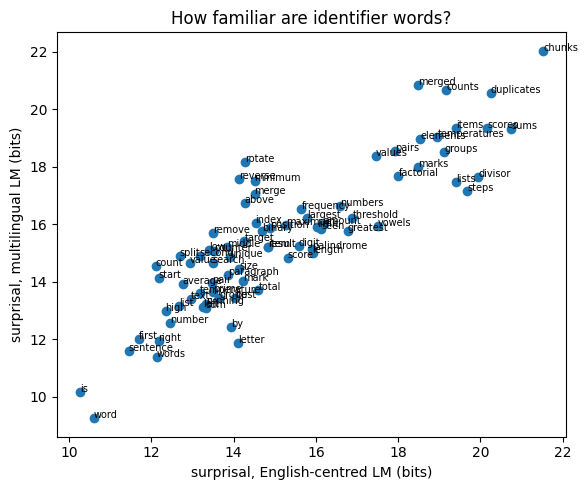

In [7]:
# Every English word used in identifiers, with its familiarity under both reader models
id_words = sorted({w for code, _ in SNIPPETS.values() for n in defined_names(code) for w in split_identifier(n) if len(w) > 1})
fam = pd.DataFrame({"word": id_words})
for key, name in [("english_lm", ENGLISH_LM), ("multi_lm", MULTI_LM)]:
    lm = load_lm(name)
    fam["surprisal_" + key] = [word_surprisal(lm, w) for w in fam["word"]]
    # Keep the multilingual model for later informativity scoring
    if key == "multi_lm":
        MULTI = lm
    else:
        free_lm(lm)
fam["length"] = fam["word"].str.len()
fam["abbreviation"] = [abbreviate(w) for w in fam["word"]]
fam.to_csv(os.path.join(OUT_DIR, "identifier_word_familiarity.csv"), index=False)
r = float(np.corrcoef(fam["surprisal_english_lm"], fam["surprisal_multi_lm"])[0, 1])
print(f"Identifier words: {len(fam)} | correlation between the two readers: {r:.3f}")
print(fam.sort_values("surprisal_english_lm", ascending=False).head(10).round(2).to_string(index=False))
# Item-level English-name cost: mean familiarity surprisal of a snippet's identifier words
fam_map = fam.set_index("word")
ITEM_COST = {}
for sname, (code, _) in SNIPPETS.items():
    ws = [w for n in defined_names(code) for w in split_identifier(n) if len(w) > 1]
    ITEM_COST[sname] = float(fam_map.loc[ws, "surprisal_english_lm"].mean()) if ws else 0.0
cost_z = pd.Series(ITEM_COST); cost_z = (cost_z - cost_z.mean()) / (cost_z.std() if cost_z.std() > 0 else 1)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(fam["surprisal_english_lm"], fam["surprisal_multi_lm"])
for _, rr in fam.iterrows():
    ax.annotate(rr["word"], (rr["surprisal_english_lm"], rr["surprisal_multi_lm"]), fontsize=7)
ax.set_xlabel("surprisal, English-centred LM (bits)"); ax.set_ylabel("surprisal, multilingual LM (bits)"); ax.set_title("How familiar are identifier words?")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_identifier_familiarity.png"), dpi=150); plt.show()

In [8]:
# Simulated classroom study: each student sees every snippet once, in one naming condition (balanced rotation)
sim = np.random.default_rng(SEED)
students = pd.DataFrame({"student": range(N_STUDENTS)})
# English proficiency between 0 and 1 (for example a normalised vocabulary test score)
students["proficiency"] = sim.beta(2.5, 2.5, N_STUDENTS)
# Programming experience as a z-score
students["experience"] = sim.normal(0, 1, N_STUDENTS)
# A noisy vocabulary test, as a teacher would actually observe it
students["vocab_test"] = (students["proficiency"] + sim.normal(0, 0.15, N_STUDENTS)).clip(0, 1)
# Available snippets (all four conditions verified)
ok_snips = [s for s in SNIPPETS if set(variants[variants["snippet"] == s]["condition"]) == set(CONDITIONS)]
# Item difficulty independent of naming
item_base = {s: sim.normal(0, 0.5) for s in ok_snips}
# Assumed generating model; the analysis below checks that it can be recovered
TRUE = {"intercept": 0.4, "experience": 0.8, "english_meaning": 0.9, "english_cost_lowprof": -0.9, "abbrev": 0.2, "abbrev_lowprof": -0.8, "roman_urdu": 0.5}
def true_logit(cond, prof, exp_, snip):
    z = TRUE["intercept"] + TRUE["experience"] * exp_ - item_base[snip]
    if cond == "english":
        z += TRUE["english_meaning"] + TRUE["english_cost_lowprof"] * cost_z[snip] * (1 - prof)
    elif cond == "abbreviated":
        z += TRUE["abbrev"] + TRUE["abbrev_lowprof"] * (1 - prof)
    elif cond == "roman_urdu":
        z += TRUE["roman_urdu"]
    return z
resp = []
for _, st in students.iterrows():
    for j, s in enumerate(ok_snips):
        cond = CONDITIONS[(int(st["student"]) + j) % len(CONDITIONS)]
        p = 1 / (1 + math.exp(-true_logit(cond, st["proficiency"], st["experience"], s)))
        resp.append({"student": int(st["student"]), "snippet": s, "condition": cond, "correct": int(sim.random() < p), "proficiency": st["proficiency"], "vocab_test": st["vocab_test"], "experience": st["experience"], "cost_z": cost_z[s]})
resp = pd.DataFrame(resp)
resp.to_csv(os.path.join(OUT_DIR, "simulated_classroom_responses.csv"), index=False)
print("Responses:", len(resp), "| overall accuracy:", round(resp["correct"].mean(), 3))
# Accuracy by condition for low and high proficiency students
resp["prof_group"] = np.where(resp["vocab_test"] < resp["vocab_test"].median(), "lower English", "higher English")
print(resp.groupby(["condition", "prof_group"])["correct"].mean().unstack().round(3).to_string())

Responses: 3200 | overall accuracy: 0.663
prof_group   higher English  lower English
condition                                 
abbreviated           0.622          0.548
english               0.782          0.792
neutral               0.600          0.568
roman_urdu            0.690          0.705


                term  estimate  ci_low  ci_high  simulated_truth
          experience     0.739   0.624    0.839              0.8
     english_meaning     1.123   0.871    1.376              0.9
english_cost_lowprof    -0.943  -1.310   -0.572             -0.9
              abbrev     0.320  -0.022    0.722              0.2
      abbrev_lowprof    -0.661  -1.373    0.043             -0.8
          roman_urdu     0.548   0.365    0.776              0.5
     low_proficiency     0.036  -0.380    0.476              NaN

(The vocabulary test is noisy, so estimates are attenuated compared with the simulated truth.)


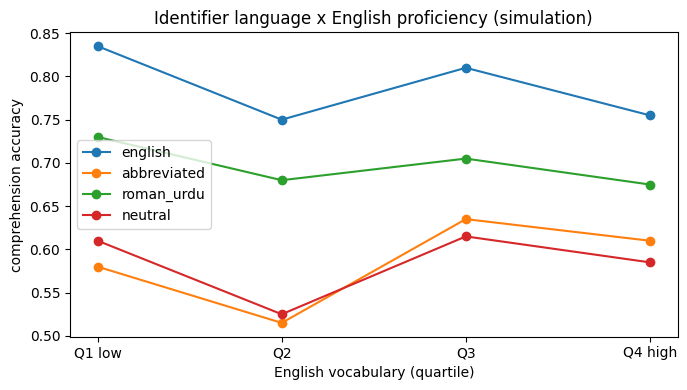

In [9]:
# Comprehension model fitted on what a teacher can observe (vocabulary test, experience, condition, item cost)
def design(df):
    low = 1 - df["vocab_test"].values
    eng = (df["condition"] == "english").values.astype(float)
    abb = (df["condition"] == "abbreviated").values.astype(float)
    rur = (df["condition"] == "roman_urdu").values.astype(float)
    return np.column_stack([df["experience"].values, eng, eng * df["cost_z"].values * low, abb, abb * low, rur, low])
COEF_NAMES = ["experience", "english_meaning", "english_cost_lowprof", "abbrev", "abbrev_lowprof", "roman_urdu", "low_proficiency"]
def fit_coefs(df):
    clf = LogisticRegression(C=100.0, max_iter=5000).fit(design(df), df["correct"].values)
    return clf.coef_[0]
est = fit_coefs(resp)
# Bootstrap over students for intervals
br = np.random.default_rng(SEED)
studs = resp["student"].unique()
by_s = {s: g for s, g in resp.groupby("student")}
boots = np.array([fit_coefs(pd.concat([by_s[s] for s in br.choice(studs, size=len(studs), replace=True)])) for _ in range(200)])
coef_table = pd.DataFrame({"term": COEF_NAMES, "estimate": est, "ci_low": np.percentile(boots, 2.5, axis=0), "ci_high": np.percentile(boots, 97.5, axis=0), "simulated_truth": [TRUE.get(t, np.nan) for t in COEF_NAMES]})
coef_table.to_csv(os.path.join(OUT_DIR, "comprehension_model.csv"), index=False)
print(coef_table.round(3).to_string(index=False))
print("\n(The vocabulary test is noisy, so estimates are attenuated compared with the simulated truth.)")
# Figure: accuracy by condition across proficiency
resp["prof_bin"] = pd.qcut(resp["vocab_test"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
tab = resp.groupby(["prof_bin", "condition"], observed=True)["correct"].mean().unstack()
fig, ax = plt.subplots(figsize=(7, 4))
for cond in CONDITIONS:
    ax.plot(tab.index.astype(str), tab[cond], marker="o", label=cond)
ax.set_xlabel("English vocabulary (quartile)"); ax.set_ylabel("comprehension accuracy"); ax.set_title("Identifier language x English proficiency (simulation)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_naming_by_proficiency.png"), dpi=150); plt.show()

In [10]:
# Explanation languages and their instructions
LANGS = {
    "english": "in simple English",
    "roman_urdu": "in Roman Urdu (Urdu written with English letters), mixing in English technical words where natural, the way Pakistani students talk. Example style: 'Yeh function har number ko check karta hai aur total mein add karta hai.'",
    "urdu_script": "in Urdu, written in Urdu script, keeping code names in English letters",
}
# Request for an explanation
def explain_request(code, lang):
    return f"Explain what this Python function does for a beginner programmer, {LANGS[lang]}. Mention the variable names you talk about.\n```python\n{code}\n```"
# Request for a back-translation into English
def back_request(text):
    return f"Translate the following explanation into English. Keep code names unchanged. Only give the translation.\n\n{text}"
# Generate explanations and back-translations
gen = load_lm(GEN_LM)
ex_snips = ok_snips[:N_EXPLAIN_SNIPPETS]
ex_rows, t0 = [], time.time()
for s in ex_snips:
    code = SNIPPETS[s][0]
    for lang in LANGS:
        text = generate(gen, explain_request(code, lang))
        back = text if lang == "english" else generate(gen, back_request(text))
        ex_rows.append({"snippet": s, "language": lang, "explanation": text, "back_translation": back})
free_lm(gen)
ex = pd.DataFrame(ex_rows)
ex.to_csv(os.path.join(OUT_DIR, "explanations_three_languages.csv"), index=False)
print("Generated", len(ex), "explanations (+ back-translations) in", round(time.time() - t0, 1), "s")
print(ex[ex["language"] == "roman_urdu"].iloc[0]["explanation"][:400])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Generated 48 explanations (+ back-translations) in 495.5 s
This function checks if a given string is a palindrome or not. It first converts all characters of the input string to lowercase using the `lower()` method. Then it compares the original string with its reverse (`text[::-1]`). If they match, it means the string is a palindrome and the function returns `True`. Otherwise, it returns `False`.

The variables used in this function are:
- `text`: This i


language               english  roman_urdu  urdu_script
metric                                                 
any_hallucination        0.188       0.000        0.062
identifier_coverage      0.897       0.767        0.984
informativity           12.716      12.396       15.947
language_compliant       1.000       0.062        0.000
similarity_to_english    1.000       0.462        0.542

Roman Urdu minus English informativity: -0.32 nats (paired permutation p = 0.847, n = 16)


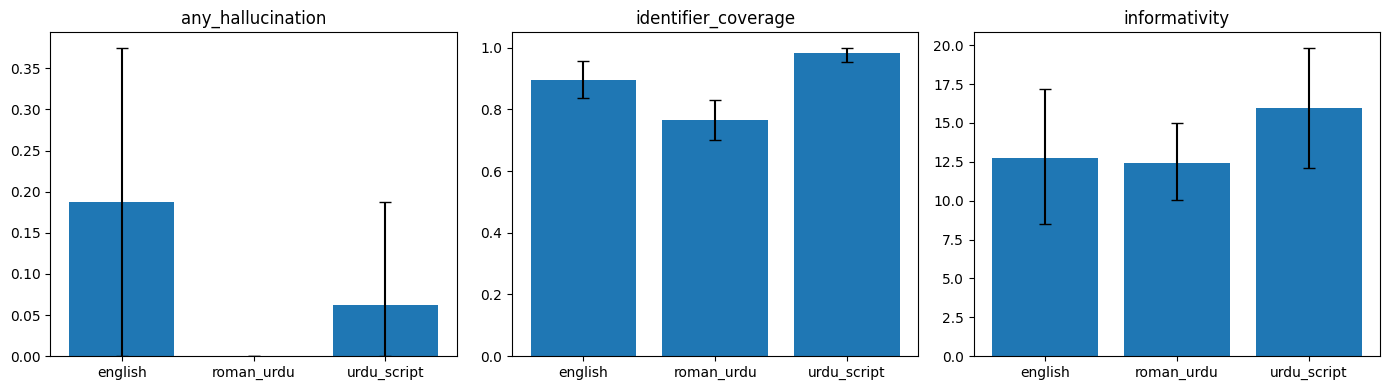

In [11]:
# Common Roman Urdu function words used to check that the output really is Roman Urdu
RU_WORDS = {"hai", "hain", "ka", "ki", "ke", "ko", "mein", "se", "aur", "yeh", "ye", "jo", "kar", "karta", "karti", "karte", "hota", "hoti", "wala", "wali", "agar", "phir", "nahi", "bhi", "tak", "liye", "kya", "ek", "har", "jab"}
# Code-like names mentioned in a text
def mentioned_ids(text):
    ids = set()
    for m in re.findall(r"`([^`]+)`", text):
        ids.update(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", m))
    ids.update(re.findall(r"\b([A-Za-z_][A-Za-z0-9_]*)\(", text))
    for w in re.findall(r"\b[A-Za-z_][A-Za-z0-9_]*\b", text):
        if "_" in w or re.search(r"[a-z][A-Z]", w):
            ids.add(w)
    return ids
# Faithfulness and language checks for one explanation
def score_explanation(row):
    code = SNIPPETS[row["snippet"]][0]
    code_ids = set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", code))
    ids = mentioned_ids(row["explanation"])
    bad = ids - code_ids - PROTECTED
    words = re.findall(r"[A-Za-z]+", row["explanation"].lower())
    letters = re.findall(r"[^\W\d_]", row["explanation"])
    urdu_share = sum("؀" <= c <= "ۿ" for c in letters) / max(len(letters), 1)
    ru_share = sum(w in RU_WORDS for w in words) / max(len(words), 1)
    if row["language"] == "english":
        compliant = urdu_share < 0.05 and ru_share < 0.05
    elif row["language"] == "roman_urdu":
        compliant = urdu_share < 0.05 and ru_share >= 0.08
    else:
        compliant = urdu_share >= 0.5
    defined = set(defined_names(code))
    return pd.Series({"n_mentioned": len(ids), "hallucinated_ids": ", ".join(sorted(bad)), "any_hallucination": float(len(bad) > 0), "identifier_coverage": len(defined & set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", row["explanation"]))) / max(len(defined), 1), "language_compliant": float(compliant), "urdu_script_share": urdu_share, "roman_urdu_share": ru_share})
ex = pd.concat([ex, ex.apply(score_explanation, axis=1)], axis=1)
# Meaning preservation: similarity of each back-translation to the English explanation of the same snippet
eng_text = ex[ex["language"] == "english"].set_index("snippet")["explanation"]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(list(ex["explanation"]) + list(ex["back_translation"]))
ex["similarity_to_english"] = [float(cosine_similarity(vec.transform([b]), vec.transform([eng_text[s]]))[0, 0]) for b, s in zip(ex["back_translation"], ex["snippet"])]
# Informativity: how much the explanation raises the multilingual model's probability of the code (nats)
base_lp = {s: continuation_logprob(MULTI, "Python code:\n", SNIPPETS[s][0]) for s in ex_snips}
ex["informativity"] = [continuation_logprob(MULTI, "Explanation: " + t[:1200] + "\n\nPython code:\n", SNIPPETS[s][0]) - base_lp[s] for t, s in zip(ex["explanation"], ex["snippet"])]
free_lm(MULTI)
ex.to_csv(os.path.join(OUT_DIR, "explanations_scored.csv"), index=False)
# Bootstrap mean and interval
def boot_ci(v, n_boot=N_BOOT, seed=SEED):
    v = np.asarray(v, dtype=float); v = v[~np.isnan(v)]; r = np.random.default_rng(seed)
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    m = [r.choice(v, size=len(v), replace=True).mean() for _ in range(n_boot)]
    return float(v.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
metrics = ["any_hallucination", "identifier_coverage", "language_compliant", "similarity_to_english", "informativity"]
lang_rows = [dict(language=l, metric=m, **dict(zip(["mean", "ci_low", "ci_high"], boot_ci(t[m])))) for l, t in ex.groupby("language") for m in metrics]
lang_table = pd.DataFrame(lang_rows)
lang_table.to_csv(os.path.join(OUT_DIR, "faithfulness_by_language.csv"), index=False)
print(lang_table.pivot(index="metric", columns="language", values="mean").round(3).to_string())
# Paired sign-flip permutation test: English vs Roman Urdu informativity on the same snippets
pairs = ex.pivot(index="snippet", columns="language", values="informativity").dropna()
dif = (pairs["roman_urdu"] - pairs["english"]).values
pr = np.random.default_rng(SEED)
perm = [(dif * pr.choice([-1, 1], size=len(dif))).mean() for _ in range(5000)]
p_inf = float((np.abs(perm) >= abs(dif.mean()) - 1e-12).mean())
print(f"\nRoman Urdu minus English informativity: {dif.mean():+.2f} nats (paired permutation p = {p_inf:.3f}, n = {len(dif)})")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, ["any_hallucination", "identifier_coverage", "informativity"]):
    t = lang_table[lang_table["metric"] == m]
    ax.bar(t["language"], t["mean"], yerr=[t["mean"] - t["ci_low"], t["ci_high"] - t["mean"]], capsize=4)
    ax.set_title(m)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig3_explanations_by_language.png"), dpi=150); plt.show()

 K  few_shot  few_shot_match  vocab_plus_few_shot  combined_match  vocab_test_only  always_english  always_roman_urdu  oracle
 1     0.677           0.781                0.684           0.862            0.685           0.564              0.677   0.693
 3     0.677           0.781                0.684           0.856            0.685           0.564              0.677   0.693
 5     0.677           0.781                0.684           0.856            0.685           0.564              0.677   0.693
10     0.677           0.781                0.683           0.838            0.685           0.564              0.677   0.693


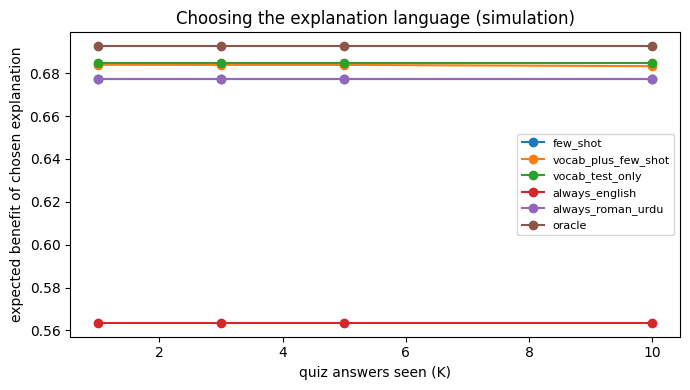

In [12]:
# Few-shot choice of explanation language for each student
# Assumed benefit of each explanation language as a function of English proficiency, scaled by measured faithfulness
FAITH = {l: 1.0 - 0.5 * float(lang_table[(lang_table["language"] == l) & (lang_table["metric"] == "any_hallucination")]["mean"].fillna(0).iloc[0]) for l in LANGS}
def benefit(lang, prof):
    z = {"english": -1.0 + 3.0 * prof, "roman_urdu": 1.0 - 0.5 * prof, "urdu_script": 0.4 - 0.4 * prof}[lang]
    return FAITH[lang] / (1 + math.exp(-z))
# Proficiency grid for the posterior
P_GRID = np.linspace(0.01, 0.99, 50)
# Likelihood of observed quiz answers for each proficiency on the grid (experience is known from a questionnaire)
def posterior_prof(obs, exp_, prior_mean=None):
    # Flat prior, or a prior centred on the vocabulary test score when one is given
    lp = np.zeros(len(P_GRID)) if prior_mean is None else -0.5 * ((P_GRID - prior_mean) / 0.15) ** 2
    for s, cond, y in obs:
        z = np.array([true_logit(cond, p, exp_, s) for p in P_GRID])
        lp += y * -np.logaddexp(0, -z) + (1 - y) * -np.logaddexp(0, z)
    post = np.exp(lp - lp.max())
    return post / post.sum()
# Evaluate policies
pol_rows = []
for _, st in students.iterrows():
    g = resp[resp["student"] == st["student"]].sample(frac=1.0, random_state=int(st["student"]))
    obs = list(zip(g["snippet"], g["condition"], g["correct"]))
    true_b = {l: benefit(l, st["proficiency"]) for l in LANGS}
    oracle = max(true_b, key=true_b.get)
    vocab_choice = max(LANGS, key=lambda l: benefit(l, st["vocab_test"]))
    for k in K_SHOTS:
        post = posterior_prof(obs[:k], st["experience"])
        exp_b = {l: float(sum(post[i] * benefit(l, P_GRID[i]) for i in range(len(P_GRID)))) for l in LANGS}
        choice = max(exp_b, key=exp_b.get)
        # Combined: vocabulary test as prior, updated with the same K answers
        post2 = posterior_prof(obs[:k], st["experience"], prior_mean=st["vocab_test"])
        exp_b2 = {l: float(sum(post2[i] * benefit(l, P_GRID[i]) for i in range(len(P_GRID)))) for l in LANGS}
        choice2 = max(exp_b2, key=exp_b2.get)
        pol_rows.append({"student": st["student"], "K": k, "few_shot": true_b[choice], "few_shot_match": float(choice == oracle), "vocab_plus_few_shot": true_b[choice2], "combined_match": float(choice2 == oracle), "vocab_test_only": true_b[vocab_choice], "always_english": true_b["english"], "always_roman_urdu": true_b["roman_urdu"], "oracle": true_b[oracle]})
pol = pd.DataFrame(pol_rows)
pol.to_csv(os.path.join(OUT_DIR, "language_choice_policies.csv"), index=False)
summ = pol.groupby("K")[["few_shot", "few_shot_match", "vocab_plus_few_shot", "combined_match", "vocab_test_only", "always_english", "always_roman_urdu", "oracle"]].mean().reset_index()
summ.to_csv(os.path.join(OUT_DIR, "language_choice_summary.csv"), index=False)
print(summ.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
for c in ["few_shot", "vocab_plus_few_shot", "vocab_test_only", "always_english", "always_roman_urdu", "oracle"]:
    ax.plot(summ["K"], summ[c], marker="o", label=c)
ax.set_xlabel("quiz answers seen (K)"); ax.set_ylabel("expected benefit of chosen explanation"); ax.set_title("Choosing the explanation language (simulation)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig4_language_choice.png"), dpi=150); plt.show()

In [13]:
# Optional real classroom data: classroom_responses.csv with columns student, snippet, condition, correct, vocab_test, experience
REAL_PATH = os.path.join(WORK_DIR, "classroom_responses.csv")
if os.path.exists(REAL_PATH):
    real = pd.read_csv(REAL_PATH)
    real = real[real["snippet"].isin(ok_snips) & real["condition"].isin(CONDITIONS)].copy()
    real["experience"] = (real["experience"] - real["experience"].mean()) / (real["experience"].std() or 1)
    # Compare the two reader models as sources of item cost (higher held-out log-likelihood = better reader model)
    out = []
    for key in ["english_lm", "multi_lm"]:
        c = {s: float(fam_map.loc[[w for n in defined_names(SNIPPETS[s][0]) for w in split_identifier(n) if len(w) > 1], "surprisal_" + key].mean()) for s in ok_snips}
        cz = pd.Series(c); cz = (cz - cz.mean()) / (cz.std() or 1)
        real["cost_z"] = real["snippet"].map(cz)
        studs_r = real["student"].unique(); ll = 0.0
        for fold in range(5):
            te = set(studs_r[fold::5])
            tr_df, te_df = real[~real["student"].isin(te)], real[real["student"].isin(te)]
            clf = LogisticRegression(C=100.0, max_iter=5000).fit(design(tr_df), tr_df["correct"].values)
            p = np.clip(clf.predict_proba(design(te_df))[:, 1], 1e-9, 1 - 1e-9)
            ll += float(np.sum(te_df["correct"] * np.log(p) + (1 - te_df["correct"]) * np.log(1 - p)))
        out.append({"reader_model": key, "heldout_loglik": ll})
        print(pd.DataFrame({"term": COEF_NAMES, "estimate": fit_coefs(real)}).round(3).to_string(index=False))
    pd.DataFrame(out).to_csv(os.path.join(OUT_DIR, "real_reader_model_comparison.csv"), index=False)
    print(pd.DataFrame(out).round(2).to_string(index=False))
else:
    print("No classroom file found; the study analysis above uses simulated students.")

No classroom file found; the study analysis above uses simulated students.


In [14]:
# Headline numbers for the proposal
summary = {
    "verified_code_variants": int(len(variants)),
    "failed_variant_checks": [list(f) for f in failures],
    "identifier_words": int(len(fam)),
    "reader_model_correlation": round(r, 4),
    "comprehension_model": coef_table.round(4).to_dict(orient="records"),
    "explanations_by_language": lang_table.round(4).to_dict(orient="records"),
    "roman_urdu_vs_english_informativity": {"mean_difference": round(float(dif.mean()), 4), "permutation_p": round(p_inf, 4)},
    "language_choice": summ.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

Saved files:
 - code_variants.csv
 - comprehension_model.csv
 - explanations_scored.csv
 - explanations_three_languages.csv
 - faithfulness_by_language.csv
 - fig1_identifier_familiarity.png
 - fig2_naming_by_proficiency.png
 - fig3_explanations_by_language.png
 - fig4_language_choice.png
 - identifier_word_familiarity.csv
 - language_choice_policies.csv
 - language_choice_summary.csv
 - simulated_classroom_responses.csv
 - summary.json
